[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L4/BA_L4_traffic_light/BA_L4_traffic_light.ipynb)

# BA_L4_traffic_light: The Basel traffic light through time

*Quantlet of Lecture 4, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Number of violations of the one-day VaR 1% of Bitcoin in the last 250 days, 2020 to 18 September 2026, for four rolling methods (Normal 250 days, historical simulation 500 days, EWMA, GARCH(1,1)-t), against the Basel green, amber and red zones.

In [1]:
# packages that are not preinstalled on Colab
import importlib, subprocess, sys
for pkg in ['arch']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

In [2]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [3]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [4]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

**Rolling forecasts.** For each day $t$ of the test period (1 January 2020 – 18 September 2026) the four methods use only data up to $t-1$:

- Normal: mean and standard deviation of the last 250 days, $\mathrm{VaR} = -(\hat\mu + \hat\sigma\,\Phi^{-1}(0.01))$;
- historical simulation (HS): minus the empirical 1% quantile of the last 500 days;
- exponentially weighted moving average (EWMA, $\lambda = 0.94$) with Normal quantile;
- GARCH(1,1)-t, re-estimated every 21 days on all data up to the previous day, filtered daily with the fixed parameters.

A **hit** (violation) is a day with $r_t < -\mathrm{VaR}_{1\%,t}$; VaR is a positive loss, $\mathrm{VaR} = -q_{0.01}$. The GARCH re-estimation takes about a minute.

**Basel traffic light.** The number of hits in the last 250 days at VaR 1%: green zone 0–4 hits, amber 5–9, red 10 or more.

**How to read.** Each line counts the hits of one method in a moving 250-day window; the background shows the zones.

In [5]:
from scipy import stats
from arch import arch_model

END = '2026-09-18'                      # last day of the estimation sample
ASSETS = {'Bitcoin': ('BTC-USD.CC', 365, BTC), 'Ethereum': ('ETH-USD.CC', 365, ETH),
          'S&P 500': ('GSPC.INDX', 252, BLUE), 'Gold': ('XAUUSD.FOREX', 252, GOLD)}


def closes(sym, end):
    # daily closes; S&P 500 and gold: Monday-Friday only, repeated closes removed
    p = daily(sym, end)
    if sym.endswith(('.INDX', '.FOREX')):
        p = p[p.index.dayofweek < 5]
        p = p[p.diff().ne(0)]
    return p


def log_returns(sym, start='2018-01-01'):
    # daily log returns in %, from `start` to END
    p = closes(sym, END)
    return (100 * np.log(p).diff()).dropna().loc[start:]

In [6]:
lam = 0.94     # RiskMetrics decay


def ewma_forecasts(r, lam=lam):
    # one-step EWMA variance forecasts: value at t = forecast for day t made at the end of day t-1;
    # started at the variance of the first 250 days; the last element is the forecast for the day after the sample
    v = r.iloc[:250].var(); out = []
    for x in r.values:
        out.append(v)
        v = lam * v + (1 - lam) * x ** 2
    return pd.Series(out, index=r.index), v

p1, p25 = 0.01, 0.025
z1, z25 = stats.norm.ppf(p1), stats.norm.ppf(p25)


def es_factor(q, p, nu):
    # f_nu(q) / p * (nu + q^2) / (nu - 1): the ES multiplier of the standard Student-t
    return stats.t.pdf(q, nu) / p * (nu + q ** 2) / (nu - 1)

In [7]:
# Bitcoin returns from 2015 provide the estimation windows; test period 1 Jan 2020 - 18 Sep 2026
full = (100 * np.log(daily('BTC-USD.CC', END)).diff()).dropna().loc['2015-01-01':]
test = full.loc['2020-01-01':]
idx = test.index
METHODS = ['Normal 250', 'HS 500', 'EWMA', 'GARCH-t']
pred = {m_: pd.Series(np.nan, index=idx) for m_ in METHODS}      # VaR 1% forecasts, positive loss in %
loc = {t_: i for i, t_ in enumerate(full.index)}
ew, _ = ewma_forecasts(full)

for t_ in idx:
    i = loc[t_]
    w250, w500 = full.iloc[i - 250:i], full.iloc[i - 500:i]
    pred['Normal 250'][t_] = -(w250.mean() + w250.std() * z1)
    pred['HS 500'][t_] = -w500.quantile(p1)
    pred['EWMA'][t_] = -np.sqrt(ew[t_]) * z1

# GARCH-t: re-estimate every 21 days on data up to t-1, filter daily with the fixed parameters
for b0 in range(0, len(idx), 21):
    t0 = idx[b0]; hist = full.iloc[:loc[t0]]
    prm = arch_model(hist, mean='Constant', vol='GARCH', p=1, q=1, dist='t').fit(disp='off').params
    seg = full.iloc[:loc[idx[min(b0 + 20, len(idx) - 1)]] + 1]
    fc = arch_model(seg, mean='Constant', vol='GARCH', p=1, q=1, dist='t').fix(prm).forecast(
        horizon=1, start=hist.index[-1], reindex=False)
    nu_b = prm['nu']; sc_b = np.sqrt((nu_b - 2) / nu_b)
    for orig, vv in fc.variance.iloc[:, 0].items():      # forecast for the day after `orig`
        j_ = loc[orig] + 1
        if j_ >= len(full) or full.index[j_] < t0:
            continue
        pred['GARCH-t'][full.index[j_]] = -(prm['mu'] + np.sqrt(vv) * sc_b * stats.t.ppf(p1, nu_b))

print(f'test period {idx[0].date()} - {idx[-1].date()}: {len(idx)} days; expected hits at 1% = {p1 * len(idx):.1f}')

test period 2020-01-01 - 2026-09-18: 2453 days; expected hits at 1% = 24.5


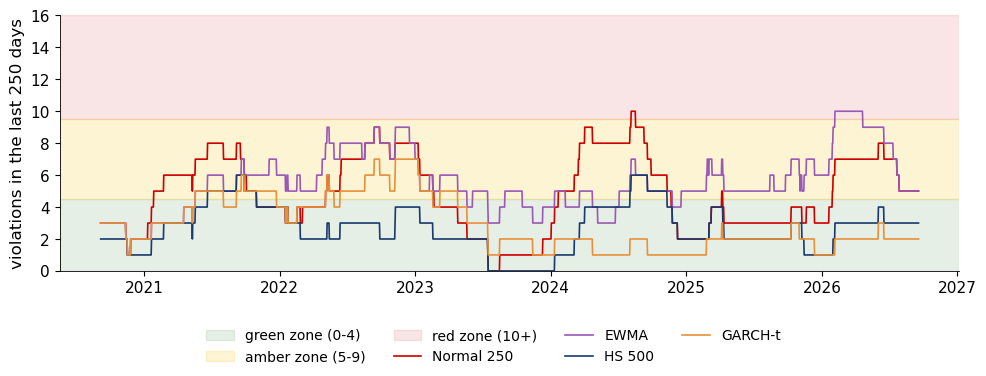

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.axhspan(0, 4.5, color=GREEN, alpha=0.12, label='green zone (0-4)')
ax.axhspan(4.5, 9.5, color='#F1C40F', alpha=0.18, label='amber zone (5-9)')
ax.axhspan(9.5, 16, color=RED, alpha=0.10, label='red zone (10+)')
zones = {}
for m_, col in [('Normal 250', RED), ('EWMA', ETH), ('HS 500', BLUE), ('GARCH-t', BTC)]:
    roll = (test < -pred[m_]).astype(int).rolling(250).sum().dropna()
    ax.plot(roll.index, roll, color=col, lw=1.2, label=m_)
    zones[m_] = {'share of days in amber or red zone (%)': 100 * (roll >= 5).mean(),
                 'share of days in red zone (%)': 100 * (roll >= 10).mean(),
                 'largest number of hits in 250 days': int(roll.max())}
ax.set_ylim(0, 16); ax.set_ylabel('violations in the last 250 days')
legend_below(fig, ncol=4); fig.tight_layout(rect=(0, 0.16, 1, 1))
save_fig(fig, 'ba_l4_traffic_light')

**Key numbers** (as on the slide).

In [9]:
pd.DataFrame(zones).T.round(1)

,share of days in amber or red zone (%),share of days in red zone (%),largest number of hits in 250 days
Normal 250,50.3,0.5,10.0
EWMA,75.6,3.4,10.0
HS 500,10.5,0.0,6.0
GARCH-t,22.9,0.0,7.0
